## 1. Install Dependencies & Hugging Face Login

In [1]:
!pip install -q bert-score tokenizers

import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
print("Hugging Face login successful.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.1 MB/s eta 0:00:00


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

CUDA available: True
GPU count: 2
GPU: Tesla T4
VRAM: 15.6 GB
Using device: cuda


## 3. Configuration

In [3]:
import os
import random
import json
import time
import math
import zipfile
import shutil
import numpy as np
from tqdm.auto import tqdm

# === Reproducibility ===
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# === Dataset ===
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

# === Model Architecture (~201M params, tied embeddings) ===
# params = emb (32000*1024 = 32.8M)
#        + 12 layers * [attn 4*d^2 (4.19M) + SwiGLU 3*d*d_ff (9.83M)]  = 168.3M
#        ≈ 201.1M
VOCAB_SIZE = 32000  # overwritten with len(tokenizer) once the tokenizer is loaded
D_MODEL = 1024
N_LAYERS = 12
N_HEADS = 16
HEAD_DIM = D_MODEL // N_HEADS  # 64
D_FF = 3200                    # SwiGLU intermediate size (~3.1x d_model)
MAX_SEQ_LEN = 1024
ROPE_BASE = 10000.0
DROPOUT = 0.0                  # <1 epoch of data, so no dropout needed

# === Training ===
TOTAL_TOKENS = 200_000_000        # 200M tokens total target
BLOCK_SIZE = 1024                 # context/sequence length for training
BATCH_SIZE = 8                    # micro batch (halved vs. the 110M model: bigger model, T4 memory)
GRADIENT_ACCUMULATION_STEPS = 8   # effective batch = 8 * 8 = 64 sequences = 65,536 tokens (unchanged)
PEAK_LR = 4e-4                    # lower than the 110M model's 6e-4: larger models need a smaller LR
MIN_LR = 4e-5                     # decay to 10% of peak (a gentler floor helps the short run)
WARMUP_STEPS = 300
WEIGHT_DECAY = 0.1
BETA1 = 0.9
BETA2 = 0.95
GRAD_CLIP = 1.0
DECAY_FRACTION = 0.10
# WSD schedule: linear warmup, stable phase, cosine decay over the last 10% of steps.
# Data sampling is plain uniform sampling (no PAS) over all pre-tokenized blocks.

# === Validation ===
VAL_TOKENS = 5_000_000        # size of the pre-tokenized validation set
VAL_INTERVAL_STEPS = 500      # evaluate every N steps
VAL_PERIODIC_BLOCKS = 256     # blocks used for the periodic (fast) validation; final eval uses ALL blocks

# === Generation (tuned for BERTScore-F1 > ROUGE-L-F1 > BLEU-4) ===
# All three metrics compare the continuation against ONE reference, so they reward the
# *most likely* continuation, not a diverse one -> low temperature, tight nucleus/top-k,
# and only a light repetition penalty (a strong one pushes the model away from legal
# terms, names and section numbers that the reference repeats, hurting ROUGE-L/BLEU-4).
TARGET_GENERATION_WORDS = 128     # reference length: BLEU brevity penalty + ROUGE/BERTScore recall need >= 128 words
MAX_GENERATION_TOKENS = 384
MIN_GENERATION_TOKENS = 240       # block EOS until we have enough tokens to reach 128 words (avoids BLEU brevity penalty)
TEMPERATURE = 0.5                 # near-mode decoding; lower (0.3) is closer to greedy but risks loops
TOP_P = 0.85
TOP_K = 40
REPETITION_PENALTY = 1.05         # light: stops degenerate loops without hurting copied legal phrasing

# === Checkpointing ===
SAVE_INTERVAL_STEPS = 2000
SAVE_TOTAL_LIMIT = 3  # keep only last N periodic checkpoints to save disk

# === Output Paths ===
OUTPUT_DIR = "/kaggle/working/cs781_phase1_no_psa"
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "legal-lm-final")
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

print("Configuration loaded.")
print(f"Effective batch size: {BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS} sequences")
print(f"Tokens per effective batch: {BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE:,}")

Configuration loaded.
Effective batch size: 64 sequences
Tokens per effective batch: 65,536


### (Optional) Smoke-test overrides
Uncomment to do a very fast end-to-end test run, then re-comment for the real run.

In [4]:
# TOTAL_TOKENS = 1_000_000
# BATCH_SIZE = 2
# GRADIENT_ACCUMULATION_STEPS = 4
# WARMUP_STEPS = 20
# VAL_INTERVAL_STEPS = 50
# VAL_PERIODIC_BLOCKS = 16
# SAVE_INTERVAL_STEPS = 100

## 4. Load Pre-tokenized Data, Tokenizer & Test File
The tokenizer and the tokenized `.bin` files were prepared beforehand and are attached as a Kaggle dataset.

In [5]:
import os
import numpy as np
from transformers import PreTrainedTokenizerFast
from huggingface_hub import hf_hub_download

# ============================================================
# 1. Dataset paths
# ============================================================

# UPDATED: Pointing to the 'm1-200m-new' dataset and its inner 'new_data' directory
DATASET_PATH = "/kaggle/input/datasets/krkanhaiya24/m1-200m-new/new_data"

CS781_DIR = os.path.join(DATASET_PATH, "cs781_phase1")
TOKENIZER_DIR = os.path.join(DATASET_PATH, "legal_tokenizer")

TRAIN_TOKENS_PATH = os.path.join(DATASET_PATH, "train_tokens.bin")
VAL_TOKENS_PATH = os.path.join(DATASET_PATH, "val_tokens.bin")

print("Dataset:", DATASET_PATH)
print("Tokenizer:", TOKENIZER_DIR)
print("Train tokens:", TRAIN_TOKENS_PATH)
print("Val tokens:", VAL_TOKENS_PATH)


# ============================================================
# 2. Verify files exist
# ============================================================

required_files = [
    os.path.join(TOKENIZER_DIR, "tokenizer.json"),
    os.path.join(TOKENIZER_DIR, "tokenizer_config.json"),
    TRAIN_TOKENS_PATH,
    VAL_TOKENS_PATH,
]

for path in required_files:
    assert os.path.exists(path), f"Missing file: {path}"

print("\nAll required files found.")


# ============================================================
# 3. Load tokenizer
# ============================================================

print("\nLoading tokenizer...")

tokenizer = PreTrainedTokenizerFast.from_pretrained(
    TOKENIZER_DIR
)

VOCAB_SIZE = len(tokenizer)

print(f"Tokenizer loaded.")
print(f"VOCAB_SIZE = {VOCAB_SIZE}")


# ============================================================
# 4. Load pre-tokenized TRAIN tokens
# ============================================================

print("\nLoading train_tokens.bin...")

train_tokens_mmap = np.memmap(
    TRAIN_TOKENS_PATH,
    dtype=np.uint32,
    mode="r"
)

print(f"Raw train tokens: {len(train_tokens_mmap):,}")

# Number of complete blocks
n_train_blocks = len(train_tokens_mmap) // BLOCK_SIZE

assert n_train_blocks > 0, (
    f"train_tokens.bin is smaller than BLOCK_SIZE={BLOCK_SIZE}"
)

train_blocks = np.asarray(
    train_tokens_mmap[:n_train_blocks * BLOCK_SIZE]
).astype(np.int64).reshape(
    n_train_blocks,
    BLOCK_SIZE
)

print(f"Train blocks: {len(train_blocks):,}")
print(f"Train shape: {train_blocks.shape}")


# ============================================================
# 5. Load pre-tokenized VALIDATION tokens
# ============================================================

print("\nLoading val_tokens.bin...")

val_tokens_mmap = np.memmap(
    VAL_TOKENS_PATH,
    dtype=np.uint32,
    mode="r"
)

print(f"Raw validation tokens: {len(val_tokens_mmap):,}")

n_val_blocks = len(val_tokens_mmap) // BLOCK_SIZE

assert n_val_blocks > 0, (
    f"val_tokens.bin is smaller than BLOCK_SIZE={BLOCK_SIZE}"
)

val_blocks = np.asarray(
    val_tokens_mmap[:n_val_blocks * BLOCK_SIZE]
).astype(np.int64).reshape(
    n_val_blocks,
    BLOCK_SIZE
)

print(f"Validation blocks: {len(val_blocks):,}")
print(f"Validation shape: {val_blocks.shape}")


# ============================================================
# 6. Token ID sanity checks
# ============================================================

print("\nRunning token ID checks...")

assert int(train_blocks.max()) < VOCAB_SIZE, (
    f"Train token ID {int(train_blocks.max())} >= "
    f"VOCAB_SIZE {VOCAB_SIZE}"
)

assert int(val_blocks.max()) < VOCAB_SIZE, (
    f"Validation token ID {int(val_blocks.max())} >= "
    f"VOCAB_SIZE {VOCAB_SIZE}"
)

assert int(train_blocks.min()) >= 0
assert int(val_blocks.min()) >= 0

print("Token ID checks passed.")


# ============================================================
# 7. Summary
# ============================================================

print("\n" + "=" * 60)
print("DATA READY")
print("=" * 60)

print(f"Vocabulary size : {VOCAB_SIZE:,}")
print(f"Block size      : {BLOCK_SIZE:,}")
print(f"Train blocks    : {len(train_blocks):,}")
print(f"Val blocks      : {len(val_blocks):,}")
print(f"Train tokens    : {len(train_blocks) * BLOCK_SIZE:,}")
print(f"Val tokens      : {len(val_blocks) * BLOCK_SIZE:,}")
print("=" * 60)

Dataset: /kaggle/input/datasets/krkanhaiya24/m1-200m-new/new_data
Tokenizer: /kaggle/input/datasets/krkanhaiya24/m1-200m-new/new_data/legal_tokenizer
Train tokens: /kaggle/input/datasets/krkanhaiya24/m1-200m-new/new_data/train_tokens.bin
Val tokens: /kaggle/input/datasets/krkanhaiya24/m1-200m-new/new_data/val_tokens.bin

All required files found.

Loading tokenizer...
Tokenizer loaded.
VOCAB_SIZE = 32000

Loading train_tokens.bin...
Raw train tokens: 122,510,035
Train blocks: 119,638
Train shape: (119638, 1024)

Loading val_tokens.bin...
Raw validation tokens: 3,081,265
Validation blocks: 3,009
Validation shape: (3009, 1024)

Running token ID checks...
Token ID checks passed.

DATA READY
Vocabulary size : 32,000
Block size      : 1,024
Train blocks    : 119,638
Val blocks      : 3,009
Train tokens    : 122,509,312
Val tokens      : 3,081,216


## 5. Uniform Data Loader & WSD Learning-Rate Scheduler
No Plasticity-Adjusted Sampling: every training block is drawn uniformly (without replacement, reshuffled each epoch) from the pooled token files.

In [6]:
class WSDScheduler:
    """Warmup-Stable-Decay learning rate scheduler."""
    def __init__(self, peak_lr, min_lr, warmup_steps, total_steps, decay_fraction=0.10):
        self.peak_lr = peak_lr
        self.min_lr = min_lr
        self.warmup_steps = warmup_steps
        self.total_steps = total_steps
        self.decay_start = int(total_steps * (1.0 - decay_fraction))
        self.decay_steps = total_steps - self.decay_start

    def get_lr(self, step):
        if step < self.warmup_steps:
            # (step + 1) so the very first optimizer step does not use LR = 0
            return self.peak_lr * (step + 1) / self.warmup_steps
        elif step < self.decay_start:
            return self.peak_lr
        else:
            progress = (step - self.decay_start) / max(self.decay_steps, 1)
            cosine_decay = 0.5 * (1.0 + math.cos(math.pi * min(progress, 1.0)))
            return self.min_lr + (self.peak_lr - self.min_lr) * cosine_decay


class UniformTrainingDataset:
    """
    Disk-backed dataset: memory-maps the pre-tokenized .bin files and serves
    uniformly shuffled fixed-length blocks (sampling without replacement;
    the order is reshuffled whenever an epoch is exhausted).
    """
    def __init__(self, bin_paths, block_size, batch_size, seed=42):
        self.block_size = block_size
        self.batch_size = batch_size
        self.rng = np.random.default_rng(seed)

        self.memmaps = []
        index_parts = []
        print("Mapping binary token files to memory...")
        for path in bin_paths:
            n_tokens = os.path.getsize(path) // 4          # uint32 = 4 bytes
            n_blocks = n_tokens // block_size
            print(f"  {os.path.basename(path)}: {n_blocks:,} blocks")
            if n_blocks == 0:
                continue                                    # np.memmap fails on empty files
            mm = np.memmap(path, dtype=np.uint32, mode="r")
            file_id = len(self.memmaps)
            self.memmaps.append(mm)
            index_parts.append(np.stack([
                np.full(n_blocks, file_id, dtype=np.int32),
                np.arange(n_blocks, dtype=np.int32),
            ], axis=1))

        assert index_parts, "No training blocks found."
        self.index = np.concatenate(index_parts, axis=0)   # (total_blocks, 2) = (file_id, block_id)
        assert len(self.index) >= batch_size, "Fewer training blocks than the batch size."
        self.order = self.rng.permutation(len(self.index))
        self.ptr = 0
        self.epoch = 0
        print(f"Total training blocks: {len(self.index):,} "
              f"({len(self.index) * block_size / 1e6:.0f}M tokens available)")

    def get_batch(self):
        """Returns a LongTensor of shape (batch_size, block_size)."""
        if self.ptr + self.batch_size > len(self.order):
            self.order = self.rng.permutation(len(self.index))
            self.ptr = 0
            self.epoch += 1
        sel = self.order[self.ptr: self.ptr + self.batch_size]
        self.ptr += self.batch_size

        blocks = []
        for j in sel:
            file_id, block_id = self.index[j]
            start = int(block_id) * self.block_size
            blocks.append(self.memmaps[file_id][start: start + self.block_size].astype(np.int64))
        return torch.from_numpy(np.stack(blocks))


# Total optimizer steps, derived from the TOTAL_TOKENS target
tokens_per_step = BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE
TOTAL_STEPS = TOTAL_TOKENS // tokens_per_step

print(f"Tokens per optimizer step: {tokens_per_step:,}")
print(f"Total optimizer steps: {TOTAL_STEPS:,}")
print(f"Warmup steps: {WARMUP_STEPS}")
print(f"Decay starts at step: {int(TOTAL_STEPS * (1 - DECAY_FRACTION))}")

lr_scheduler = WSDScheduler(
    peak_lr=PEAK_LR,
    min_lr=MIN_LR,
    warmup_steps=WARMUP_STEPS,
    total_steps=TOTAL_STEPS,
    decay_fraction=DECAY_FRACTION,
)

# UPDATED: Pointing to the new train_tokens.bin path
TRAIN_BIN_PATHS = [
    "/kaggle/input/datasets/krkanhaiya24/m1-200m-new/new_data/train_tokens.bin"
]

train_dataset = UniformTrainingDataset(
    bin_paths=TRAIN_BIN_PATHS,
    block_size=BLOCK_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED,
)

print("\n--- LR Schedule Sanity Check ---")
for s in [0, WARMUP_STEPS // 2, WARMUP_STEPS, TOTAL_STEPS // 2, int(TOTAL_STEPS * 0.9), TOTAL_STEPS - 1]:
    print(f"  Step {s:>6d}: LR={lr_scheduler.get_lr(s):.2e}")

Tokens per optimizer step: 65,536
Total optimizer steps: 3,051
Warmup steps: 300
Decay starts at step: 2745
Mapping binary token files to memory...
  train_tokens.bin: 119,638 blocks
Total training blocks: 119,638 (123M tokens available)

--- LR Schedule Sanity Check ---
  Step      0: LR=1.33e-06
  Step    150: LR=2.01e-04
  Step    300: LR=4.00e-04
  Step   1525: LR=4.00e-04
  Step   2745: LR=4.00e-04
  Step   3050: LR=4.00e-05


## 6. Model Components: RMSNorm

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class RMSNorm(nn.Module):
    """Root Mean Square Layer Normalization."""
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    
    def forward(self, x):
        # x: (batch, seq_len, dim)
        rms = torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + self.eps)
        return (x.float() * rms).type_as(x) * self.weight

## 7. Model Components: RoPE

In [8]:
def precompute_rope_freqs(dim, max_seq_len, base=10000.0):
    """Precompute the complex exponentials for RoPE."""
    # dim should be head_dim
    freqs = 1.0 / (base ** (torch.arange(0, dim, 2).float() / dim))
    t = torch.arange(max_seq_len, dtype=torch.float32)
    freqs = torch.outer(t, freqs)  # (max_seq_len, dim//2)
    # Create complex numbers: cos + i*sin
    freqs_cos = torch.cos(freqs)  # (max_seq_len, dim//2)
    freqs_sin = torch.sin(freqs)  # (max_seq_len, dim//2)
    return freqs_cos, freqs_sin


def apply_rope(x, freqs_cos, freqs_sin):
    """
    Apply rotary position embeddings to x.
    x: (batch, n_heads, seq_len, head_dim)
    freqs_cos, freqs_sin: (seq_len, head_dim//2)
    """
    # Split x into pairs for rotation
    x_r = x.float().reshape(*x.shape[:-1], -1, 2)  # (..., head_dim//2, 2)
    x0 = x_r[..., 0]  # (..., head_dim//2)
    x1 = x_r[..., 1]  # (..., head_dim//2)
    
    # Get the right slice of freqs for the sequence length
    seq_len = x.shape[2]
    cos = freqs_cos[:seq_len].unsqueeze(0).unsqueeze(0)  # (1, 1, seq_len, head_dim//2)
    sin = freqs_sin[:seq_len].unsqueeze(0).unsqueeze(0)  # (1, 1, seq_len, head_dim//2)
    
    # Apply rotation
    out0 = x0 * cos - x1 * sin
    out1 = x0 * sin + x1 * cos
    
    # Interleave back
    out = torch.stack([out0, out1], dim=-1).reshape_as(x)
    return out.type_as(x)

## 8. Model Components: Causal Self-Attention

In [9]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, head_dim, dropout=0.0):
        super().__init__()
        self.n_heads = n_heads
        self.head_dim = head_dim
        self.d_model = d_model
        
        # QKV projections (no bias, following LLaMA)
        self.q_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.k_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.v_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.out_proj = nn.Linear(n_heads * head_dim, d_model, bias=False)
        
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
    
    def forward(self, x, freqs_cos, freqs_sin):
        """
        x: (batch, seq_len, d_model)
        Returns: (batch, seq_len, d_model)
        """
        B, T, C = x.shape
        
        q = self.q_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)  # (B, nh, T, hd)
        k = self.k_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        
        # Apply RoPE to Q and K
        q = apply_rope(q, freqs_cos, freqs_sin)
        k = apply_rope(k, freqs_cos, freqs_sin)
        
        # Scaled dot-product attention with causal mask
        # Use PyTorch's native scaled_dot_product_attention for efficiency (flash attention when available)
        out = F.scaled_dot_product_attention(
            q, k, v,
            attn_mask=None,
            dropout_p=self.attn_dropout.p if self.training else 0.0,
            is_causal=True,
        )  # (B, nh, T, hd)
        
        out = out.transpose(1, 2).contiguous().view(B, T, self.n_heads * self.head_dim)  # (B, T, C)
        out = self.resid_dropout(self.out_proj(out))
        return out

## 9. Model Components: SwiGLU FFN

In [10]:
class SwiGLU_FFN(nn.Module):
    """SwiGLU feed-forward network (LLaMA-style)."""
    def __init__(self, d_model, d_ff, dropout=0.0):
        super().__init__()
        # SwiGLU: gate = silu(W_gate @ x), up = W_up @ x, out = W_down @ (gate * up)
        self.w_gate = nn.Linear(d_model, d_ff, bias=False)
        self.w_up = nn.Linear(d_model, d_ff, bias=False)
        self.w_down = nn.Linear(d_ff, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x):
        gate = F.silu(self.w_gate(x))
        up = self.w_up(x)
        return self.dropout(self.w_down(gate * up))

## 10. Model Components: Transformer Block

In [11]:
class TransformerBlock(nn.Module):
    """Pre-norm Transformer decoder block with RoPE attention + SwiGLU FFN."""
    def __init__(self, d_model, n_heads, head_dim, d_ff, dropout=0.0):
        super().__init__()
        self.attn_norm = RMSNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads, head_dim, dropout)
        self.ffn_norm = RMSNorm(d_model)
        self.ffn = SwiGLU_FFN(d_model, d_ff, dropout)
    
    def forward(self, x, freqs_cos, freqs_sin):
        # Pre-norm + attention + residual
        x = x + self.attn(self.attn_norm(x), freqs_cos, freqs_sin)
        # Pre-norm + FFN + residual
        x = x + self.ffn(self.ffn_norm(x))
        return x

## 11. Full Model: LegalLM

In [12]:
from torch.utils.checkpoint import checkpoint as grad_checkpoint

class LegalLM(nn.Module):
    """
    Decoder-only Transformer Language Model for legal text.
    Architecture: RoPE + RMSNorm + SwiGLU (LLaMA-style), trained from scratch.
    """
    def __init__(self, vocab_size, d_model, n_layers, n_heads, head_dim, d_ff,
                 max_seq_len, rope_base=10000.0, dropout=0.0,
                 use_gradient_checkpointing=True):
        super().__init__()
        self.d_model = d_model
        self.n_layers = n_layers
        self.max_seq_len = max_seq_len
        self.use_gradient_checkpointing = use_gradient_checkpointing
        self.vocab_size = vocab_size

        # Token embedding (no positional embedding -- RoPE is in attention)
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.emb_dropout = nn.Dropout(dropout)

        # Transformer blocks
        self.layers = nn.ModuleList([
            TransformerBlock(d_model, n_heads, head_dim, d_ff, dropout)
            for _ in range(n_layers)
        ])

        # Final norm
        self.final_norm = RMSNorm(d_model)

        # LM head (tied with embedding)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight  # weight tying

        # Precompute RoPE frequencies
        freqs_cos, freqs_sin = precompute_rope_freqs(head_dim, max_seq_len, rope_base)
        self.register_buffer("freqs_cos", freqs_cos, persistent=False)
        self.register_buffer("freqs_sin", freqs_sin, persistent=False)

        self._init_weights()

    def _init_weights(self):
        """Initialize weights with small normal distribution (GPT-2 style)."""
        for module in self.modules():
            if isinstance(module, nn.Linear):
                torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
                if module.bias is not None:
                    torch.nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Embedding):
                torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

        # Scale residual projections by 1/sqrt(2*n_layers) for stability
        for layer in self.layers:
            torch.nn.init.normal_(layer.attn.out_proj.weight, mean=0.0,
                                  std=0.02 / math.sqrt(2 * self.n_layers))
            torch.nn.init.normal_(layer.ffn.w_down.weight, mean=0.0,
                                  std=0.02 / math.sqrt(2 * self.n_layers))

    def forward(self, input_ids, targets=None, last_only=False):
        """
        input_ids: (batch, seq_len)
        targets:   (batch, seq_len) -- usually identical to input_ids; the shift is done here
        last_only: return logits for the final position only (fast path for generation)

        Returns: (logits, loss); loss is None if targets is None
        """
        B, T = input_ids.shape
        assert T <= self.max_seq_len, f"Sequence length {T} > max {self.max_seq_len}"

        x = self.emb_dropout(self.tok_emb(input_ids))  # (B, T, d_model)

        for layer in self.layers:
            if self.use_gradient_checkpointing and self.training:
                x = grad_checkpoint(
                    layer, x, self.freqs_cos, self.freqs_sin,
                    use_reentrant=False,
                )
            else:
                x = layer(x, self.freqs_cos, self.freqs_sin)

        x = self.final_norm(x)  # (B, T, d_model)

        if last_only and targets is None:
            x = x[:, -1:, :]

        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            # logits[:, :-1] predicts targets[:, 1:]
            loss = F.cross_entropy(
                logits[:, :-1, :].reshape(-1, self.vocab_size),
                targets[:, 1:].reshape(-1),
                ignore_index=-100,
            )

        return logits, loss

    @torch.no_grad()
    def generate(self, input_ids, max_new_tokens, temperature=0.7, top_p=0.9,
                 top_k=50, repetition_penalty=1.1, eos_token_id=None, min_new_tokens=0):
        """
        Autoregressive generation with repetition penalty, temperature, top-k and top-p.
        input_ids: (batch, seq_len)  ->  returns (batch, seq_len + n_generated)
        """
        self.eval()
        use_amp = input_ids.is_cuda

        for step_i in range(max_new_tokens):
            idx_cond = input_ids[:, -self.max_seq_len:]

            with torch.amp.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                logits, _ = self(idx_cond, last_only=True)
            logits = logits[:, -1, :].float()  # (B, vocab_size)

            # Repetition penalty (vectorised): penalise every token already in the context
            if repetition_penalty != 1.0:
                score = torch.gather(logits, 1, input_ids)
                score = torch.where(score > 0, score / repetition_penalty, score * repetition_penalty)
                logits.scatter_(1, input_ids, score)

            # Don't allow EOS before min_new_tokens
            if eos_token_id is not None and step_i < min_new_tokens:
                logits[:, eos_token_id] = float("-inf")

            # Temperature
            logits = logits / temperature

            # Top-k
            if top_k > 0:
                k = min(top_k, logits.size(-1))
                kth_vals = torch.topk(logits, k).values[:, -1:]
                logits = logits.masked_fill(logits < kth_vals, float("-inf"))

            # Top-p (nucleus), vectorised
            if top_p < 1.0:
                sorted_logits, sorted_idx = torch.sort(logits, descending=True)
                cum_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
                remove = cum_probs > top_p
                remove[:, 1:] = remove[:, :-1].clone()   # keep the first token above the threshold
                remove[:, 0] = False
                sorted_logits = sorted_logits.masked_fill(remove, float("-inf"))
                logits = torch.full_like(logits, float("-inf")).scatter(1, sorted_idx, sorted_logits)

            probs = F.softmax(logits, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)  # (B, 1)
            input_ids = torch.cat([input_ids, next_token], dim=1)

            if eos_token_id is not None and (next_token == eos_token_id).all():
                break

        return input_ids


# === Instantiate Model ===
model = LegalLM(
    vocab_size=VOCAB_SIZE,
    d_model=D_MODEL,
    n_layers=N_LAYERS,
    n_heads=N_HEADS,
    head_dim=HEAD_DIM,
    d_ff=D_FF,
    max_seq_len=MAX_SEQ_LEN,
    rope_base=ROPE_BASE,
    dropout=DROPOUT,
    use_gradient_checkpointing=True,
)
model = model.to(device)

# model.parameters() already de-duplicates the tied embedding / lm_head weight,
# so this is the true parameter count (the old notebook subtracted the embedding again).
unique_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters (tied weights counted once): {unique_params:,} ({unique_params/1e6:.1f}M)")
print(f"  of which embedding / LM head: {model.tok_emb.weight.numel()/1e6:.1f}M")

assert 50_000_000 <= unique_params <= 300_000_000, \
    f"Model has {unique_params/1e6:.1f}M params, must be 50-300M!"
print("Model size within allowed range.")

Total parameters (tied weights counted once): 201,090,048 (201.1M)
  of which embedding / LM head: 32.8M
Model size within allowed range.


## 12. Optimizer & Mixed Precision Setup

In [13]:
# AdamW with parameter groups (no weight decay on norms, biases and embeddings)
decay_params = []
no_decay_params = []

for name, param in model.named_parameters():
    if not param.requires_grad:
        continue
    if "norm" in name or "bias" in name or "tok_emb" in name:
        no_decay_params.append(param)
    else:
        decay_params.append(param)

optimizer = torch.optim.AdamW([
    {"params": decay_params, "weight_decay": WEIGHT_DECAY},
    {"params": no_decay_params, "weight_decay": 0.0},
], lr=PEAK_LR, betas=(BETA1, BETA2))

print(f"Optimizer groups: {len(decay_params)} decay params, {len(no_decay_params)} no-decay params")

# Mixed precision (FP16) loss scaler - new torch.amp API (torch.cuda.amp.GradScaler is deprecated)
scaler = torch.amp.GradScaler("cuda")
print("Mixed precision (FP16) enabled.")

Optimizer groups: 84 decay params, 26 no-decay params
Mixed precision (FP16) enabled.


## 13. Validation Function

In [14]:
@torch.no_grad()
def evaluate_val(model, val_blocks, device, block_indices=None, eval_batch_size=8):
    """
    Evaluate on validation blocks (numpy array of shape (N, BLOCK_SIZE)).
    block_indices: optional subset of block indices (None = all blocks).
    Returns (average loss, perplexity); the average is weighted per sequence.
    """
    was_training = model.training
    model.eval()

    if block_indices is None:
        block_indices = np.arange(len(val_blocks))

    total_loss = 0.0
    total_seqs = 0

    for i in tqdm(range(0, len(block_indices), eval_batch_size), desc="Validation", leave=False):
        idx = block_indices[i:i + eval_batch_size]
        input_ids = torch.from_numpy(val_blocks[idx]).to(device)

        with torch.amp.autocast("cuda", dtype=torch.float16):
            _, loss = model(input_ids, targets=input_ids)

        total_loss += loss.item() * input_ids.size(0)
        total_seqs += input_ids.size(0)

    avg_loss = total_loss / total_seqs
    perplexity = math.exp(min(avg_loss, 20))  # cap to avoid overflow

    if was_training:
        model.train()
    return avg_loss, perplexity


# Fixed, evenly spaced subset for the periodic (fast) validation, so the numbers are comparable across steps
n_periodic = min(VAL_PERIODIC_BLOCKS, len(val_blocks))
val_subset_idx = np.linspace(0, len(val_blocks) - 1, n_periodic).astype(int)
print(f"Periodic validation uses {n_periodic} of {len(val_blocks)} blocks; final evaluation uses all.")

Periodic validation uses 256 of 3009 blocks; final evaluation uses all.


## 14. Checkpoint Save/Load

In [15]:
def save_checkpoint(model, optimizer, scaler, step, loss, path):
    """Save a training checkpoint."""
    checkpoint = {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "step": step,
        "loss": loss,
        "config": {
            "vocab_size": VOCAB_SIZE,
            "d_model": D_MODEL,
            "n_layers": N_LAYERS,
            "n_heads": N_HEADS,
            "head_dim": HEAD_DIM,
            "d_ff": D_FF,
            "max_seq_len": MAX_SEQ_LEN,
            "rope_base": ROPE_BASE,
            "dropout": DROPOUT,
        }
    }
    torch.save(checkpoint, path)
    print(f"  Checkpoint saved: step {step}, loss {loss:.4f}")


def load_checkpoint(path, model, optimizer=None, scaler=None):
    """Load a training checkpoint."""
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    if optimizer is not None and "optimizer_state_dict" in checkpoint:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    if scaler is not None and "scaler_state_dict" in checkpoint:
        scaler.load_state_dict(checkpoint["scaler_state_dict"])
    return checkpoint["step"], checkpoint.get("loss", None)


def cleanup_checkpoints(checkpoint_dir, keep_last_n=3):
    """Keep only the last N checkpoints to save disk space."""
    ckpts = sorted(
        [f for f in os.listdir(checkpoint_dir) if f.startswith("step_") and f.endswith(".pt")],
        key=lambda x: int(x.split("_")[1].split(".")[0])
    )
    while len(ckpts) > keep_last_n:
        oldest = ckpts.pop(0)
        os.remove(os.path.join(checkpoint_dir, oldest))
        print(f"  Deleted old checkpoint: {oldest}")

## 15. Training Loop (uniform sampling, no PAS)

In [16]:
# 1. Define the exact path to the latest checkpoint
ckpt_path = "/kaggle/input/datasets/unknownjartrexer1067/m5-ckpts/cs781_phase1_no_psa/checkpoints/step_3051.pt"

# 2. Load the checkpoint dictionary
print(f"Loading checkpoint from {ckpt_path}...")
checkpoint = torch.load(ckpt_path, map_location=device)

# 3. Restore states
model.load_state_dict(checkpoint.get("model_state_dict", checkpoint)) 
if "optimizer_state_dict" in checkpoint:
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
if "scaler_state_dict" in checkpoint:
    scaler.load_state_dict(checkpoint["scaler_state_dict"])

# 4. Set the starting step 
start_step = checkpoint.get("step", 3051)

# ---------------------------------------------------------
# NEW: Extend training by adding 3051 more steps
# ---------------------------------------------------------
ADDITIONAL_STEPS = 3051
TOTAL_STEPS = start_step + ADDITIONAL_STEPS
TOTAL_TOKENS = TOTAL_STEPS * BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE

# Stretch the WSD learning rate schedule across the new horizon so it doesn't instantly decay
lr_scheduler.total_steps = TOTAL_STEPS
lr_scheduler.decay_start = int(TOTAL_STEPS * (1.0 - DECAY_FRACTION))
lr_scheduler.decay_steps = TOTAL_STEPS - lr_scheduler.decay_start
# ---------------------------------------------------------

# 5. Restore tokens_seen to maintain accurate TPS logging
tokens_seen = start_step * BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE

print(f"Resumed training from step {start_step}. Target extended to: {TOTAL_STEPS} steps.")

Loading checkpoint from /kaggle/input/datasets/unknownjartrexer1067/m5-ckpts/cs781_phase1_no_psa/checkpoints/step_3051.pt...
Resumed training from step 3051. Target extended to: 6102 steps.


In [17]:
model.train()

train_log = []  # {"step", "loss", "lr", "tokens_seen"}
val_log = []    # {"step", "val_loss", "val_ppl"}
best_val_loss = float("inf")
best_step = 0

print(f"Starting training for {TOTAL_STEPS} optimizer steps...")
print(f"Target: {TOTAL_TOKENS:,} tokens\n")

start_time = time.time()
running_loss = 0.0
tokens_seen = 0
avg_loss = float("nan")

for step in tqdm(range(start_step, TOTAL_STEPS), desc="Training Steps"):
# for step in tqdm(range(TOTAL_STEPS), desc="Training Steps"):
    # === Learning rate for this step ===
    current_lr = lr_scheduler.get_lr(step)
    for param_group in optimizer.param_groups:
        param_group["lr"] = current_lr

    # === Gradient accumulation ===
    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0

    for micro_step in range(GRADIENT_ACCUMULATION_STEPS):
        batch = train_dataset.get_batch().to(device, non_blocking=True)  # (BATCH_SIZE, BLOCK_SIZE)

        with torch.amp.autocast("cuda", dtype=torch.float16):
            _, loss = model(batch, targets=batch)
            loss_scaled = loss / GRADIENT_ACCUMULATION_STEPS

        scaler.scale(loss_scaled).backward()
        accum_loss += loss.item()

    # Gradient clipping (unscale first so the threshold is in true gradient units)
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)

    scaler.step(optimizer)
    scaler.update()

    avg_loss = accum_loss / GRADIENT_ACCUMULATION_STEPS
    running_loss += avg_loss
    tokens_seen += BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE

    # === Logging (every 100 steps) ===
    if (step + 1) % 100 == 0:
        elapsed = time.time() - start_time
        tps = tokens_seen / elapsed
        avg_running = running_loss / 100

        train_log.append({
            "step": step + 1,
            "loss": avg_running,
            "lr": current_lr,
            "tokens_seen": tokens_seen,
        })

        tqdm.write(f"Step {step+1:>6d}/{TOTAL_STEPS} | "
                   f"Loss: {avg_running:.4f} | "
                   f"LR: {current_lr:.2e} | "
                   f"Tok: {tokens_seen/1e6:.0f}M | "
                   f"Speed: {tps:,.0f} tok/s | "
                   f"ETA: {(TOTAL_STEPS - step - 1) / (step + 1) * elapsed / 3600:.1f}h")

        running_loss = 0.0

    # === Validation ===
    if (step + 1) % VAL_INTERVAL_STEPS == 0:
        val_loss, val_ppl = evaluate_val(model, val_blocks, device, block_indices=val_subset_idx)
        val_log.append({"step": step + 1, "val_loss": val_loss, "val_ppl": val_ppl})
        tqdm.write(f"  >>> VAL: loss={val_loss:.4f}, ppl={val_ppl:.2f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_step = step + 1
            save_checkpoint(model, optimizer, scaler, step + 1, val_loss,
                            os.path.join(CHECKPOINT_DIR, "best.pt"))
            tqdm.write(f"  >>> New best model at step {step+1}!")

    # === Periodic checkpointing ===
    if (step + 1) % SAVE_INTERVAL_STEPS == 0:
        ckpt_path = os.path.join(CHECKPOINT_DIR, f"step_{step+1}.pt")
        save_checkpoint(model, optimizer, scaler, step + 1, avg_loss, ckpt_path)
        cleanup_checkpoints(CHECKPOINT_DIR, keep_last_n=SAVE_TOTAL_LIMIT)

# === End of training: one validation on the final weights (so best.pt always exists) ===
val_loss, val_ppl = evaluate_val(model, val_blocks, device, block_indices=val_subset_idx)
val_log.append({"step": TOTAL_STEPS, "val_loss": val_loss, "val_ppl": val_ppl})
print(f"Final-step VAL: loss={val_loss:.4f}, ppl={val_ppl:.2f}")
if val_loss < best_val_loss:
    best_val_loss = val_loss
    best_step = TOTAL_STEPS
    save_checkpoint(model, optimizer, scaler, TOTAL_STEPS, val_loss,
                    os.path.join(CHECKPOINT_DIR, "best.pt"))

save_checkpoint(model, optimizer, scaler, TOTAL_STEPS, avg_loss,
                os.path.join(CHECKPOINT_DIR, f"step_{TOTAL_STEPS}.pt"))

total_time = time.time() - start_time
print(f"\n{'='*60}")
print("Training complete!")
print(f"Total time: {total_time / 3600:.2f} hours")
print(f"Total tokens: {tokens_seen:,}")
print(f"Average speed: {tokens_seen / total_time:,.0f} tokens/sec")
print(f"Best validation loss: {best_val_loss:.4f} at step {best_step}")

Starting training for 6102 optimizer steps...
Target: 399,900,672 tokens



Training Steps:   0%|          | 0/3051 [00:00<?, ?it/s]

Step   3100/6102 | Loss: 1.1645 | LR: 4.00e-04 | Tok: 3M | Speed: 7,692 tok/s | ETA: 0.1h
Step   3200/6102 | Loss: 2.2268 | LR: 4.00e-04 | Tok: 10M | Speed: 7,683 tok/s | ETA: 0.3h
Step   3300/6102 | Loss: 2.1626 | LR: 4.00e-04 | Tok: 16M | Speed: 7,681 tok/s | ETA: 0.5h
Step   3400/6102 | Loss: 2.1160 | LR: 4.00e-04 | Tok: 23M | Speed: 7,681 tok/s | ETA: 0.7h
Step   3500/6102 | Loss: 2.1073 | LR: 4.00e-04 | Tok: 29M | Speed: 7,681 tok/s | ETA: 0.8h


Validation:   0%|          | 0/32 [00:00<?, ?it/s]

  >>> VAL: loss=2.0055, ppl=7.43
  Checkpoint saved: step 3500, loss 2.0055
  >>> New best model at step 3500!
Step   3600/6102 | Loss: 2.0663 | LR: 4.00e-04 | Tok: 36M | Speed: 7,662 tok/s | ETA: 0.9h
Step   3700/6102 | Loss: 2.0533 | LR: 4.00e-04 | Tok: 43M | Speed: 7,665 tok/s | ETA: 1.0h
Step   3800/6102 | Loss: 2.0490 | LR: 4.00e-04 | Tok: 49M | Speed: 7,667 tok/s | ETA: 1.1h
Step   3900/6102 | Loss: 2.0258 | LR: 4.00e-04 | Tok: 56M | Speed: 7,668 tok/s | ETA: 1.1h
Step   4000/6102 | Loss: 2.0069 | LR: 4.00e-04 | Tok: 62M | Speed: 7,670 tok/s | ETA: 1.2h


Validation:   0%|          | 0/32 [00:00<?, ?it/s]

... (7 outputs left out)

Validation:   0%|          | 0/32 [00:00<?, ?it/s]

  >>> VAL: loss=1.7379, ppl=5.69
  Checkpoint saved: step 6000, loss 1.7379
  >>> New best model at step 6000!
  Checkpoint saved: step 6000, loss 1.6186
Step   6100/6102 | Loss: 1.6850 | LR: 4.00e-05 | Tok: 200M | Speed: 7,657 tok/s | ETA: 0.0h


Validation:   0%|          | 0/32 [00:00<?, ?it/s]

Final-step VAL: loss=1.7258, ppl=5.62
  Checkpoint saved: step 6102, loss 1.7258
  Checkpoint saved: step 6102, loss 1.7015

Training complete!
Total time: 7.26 hours
Total tokens: 199,950,336
Average speed: 7,653 tokens/sec
Best validation loss: 1.7258 at step 6102


## 16. Plot Training & Validation Loss

In [18]:
# fff

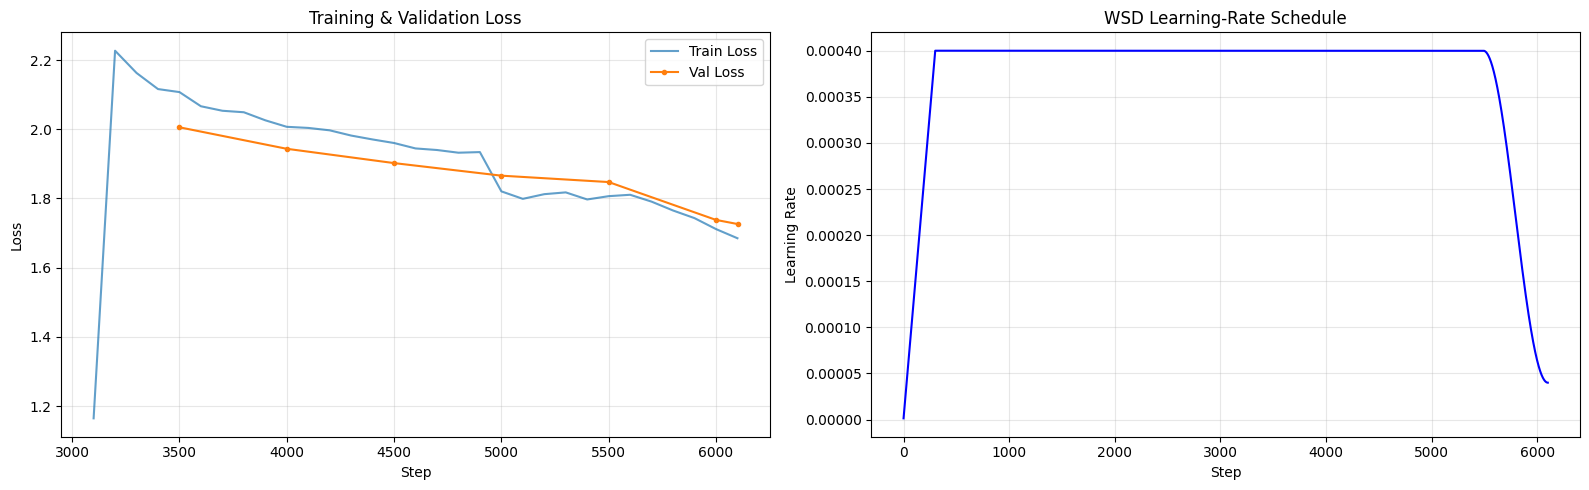

Loss plot saved to: /kaggle/working/cs781_phase1_no_psa/training_validation_loss.png


In [19]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

train_steps_log = [d["step"] for d in train_log]
train_loss_log = [d["loss"] for d in train_log]
val_steps_log = [d["step"] for d in val_log]
val_loss_log = [d["val_loss"] for d in val_log]

# Plot 1: loss curves
ax1.plot(train_steps_log, train_loss_log, label="Train Loss", alpha=0.7)
ax1.plot(val_steps_log, val_loss_log, label="Val Loss", marker="o", markersize=3)
ax1.set_xlabel("Step")
ax1.set_ylabel("Loss")
ax1.set_title("Training & Validation Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: learning-rate schedule (full schedule, not just logged steps)
all_steps = list(range(TOTAL_STEPS))
ax2.plot(all_steps, [lr_scheduler.get_lr(s) for s in all_steps], color="blue")
ax2.set_xlabel("Step")
ax2.set_ylabel("Learning Rate")
ax2.set_title("WSD Learning-Rate Schedule")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200, bbox_inches="tight")
plt.show()
print(f"Loss plot saved to: {LOSS_PLOT_PATH}")

## 17. Final Validation Perplexity (best checkpoint, all validation blocks)

In [20]:
# ==========================================
# 17. Final Validation Perplexity (best checkpoint, all validation blocks)
# ==========================================

print("Loading best checkpoint for evaluation...")

# Point directly to the uploaded checkpoint in your dataset instead of CHECKPOINT_DIR
ckpt_path = "/kaggle/input/datasets/unknownjartrexer1067/m5-ckpts/cs781_phase1_no_psa/checkpoints/best.pt"

# Use your existing load_checkpoint function from Step 14
best_step, best_val_loss = load_checkpoint(ckpt_path, model)

print(f"Loaded best checkpoint from step {best_step}, loss {best_val_loss:.4f}")

# Full validation over ALL blocks
final_val_loss, final_val_ppl = evaluate_val(model, val_blocks, device)
print(f"\nFinal Validation Loss: {final_val_loss:.6f}")
print(f"Final Validation Perplexity: {final_val_ppl:.4f}")

Loading best checkpoint for evaluation...
Loaded best checkpoint from step 3051, loss 2.0663


Validation:   0%|          | 0/377 [00:00<?, ?it/s]


Final Validation Loss: 2.618176
Final Validation Perplexity: 13.7107


In [21]:
# print("Loading best checkpoint for evaluation...")
# best_step_loaded, best_loss_loaded = load_checkpoint(
#     os.path.join(CHECKPOINT_DIR, "best.pt"), model
# )
# print(f"Loaded best checkpoint from step {best_step_loaded}, loss {best_loss_loaded:.4f}")

# # Full validation over ALL blocks
# final_val_loss, final_val_ppl = evaluate_val(model, val_blocks, device)
# print(f"\nFinal Validation Loss: {final_val_loss:.6f}")
# print(f"Final Validation Perplexity: {final_val_ppl:.4f}")

## 18. Save Final Model & Tokenizer

In [22]:
# ==========================================
# 18. Save Final Model & Tokenizer
# ==========================================

import json
import os
import torch

# Reconstruct tokens_seen mathematically since it is not in memory
tokens_seen = best_step * BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE

model_config = {
    "vocab_size": VOCAB_SIZE,
    "d_model": D_MODEL,
    "n_layers": N_LAYERS,
    "n_heads": N_HEADS,
    "head_dim": HEAD_DIM,
    "d_ff": D_FF,
    "max_seq_len": MAX_SEQ_LEN,
    "rope_base": ROPE_BASE,
    "dropout": DROPOUT,
}

torch.save({
    "model_state_dict": model.state_dict(),
    "config": model_config,
    "training_info": {
        "total_tokens": tokens_seen,
        "best_val_loss": best_val_loss,
        "best_step": best_step,
        "final_full_val_loss": final_val_loss,
        "sampling": "uniform (no PAS)",
    },
}, os.path.join(MODEL_OUTPUT_DIR, "model.pt"))

with open(os.path.join(MODEL_OUTPUT_DIR, "config.json"), "w") as f:
    json.dump({
        **model_config,
        "architecture": "decoder-only-llama-style",
        "components": "RoPE + RMSNorm + SwiGLU + tied_embeddings",
    }, f, indent=2)

tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

print(f"Final model saved to: {MODEL_OUTPUT_DIR}")
print(f"Files: {os.listdir(MODEL_OUTPUT_DIR)}")

Final model saved to: /kaggle/working/cs781_phase1_no_psa/legal-lm-final
Files: ['tokenizer_config.json', 'tokenizer.json', 'config.json', 'model.pt']


In [23]:
# model_config = {
#     "vocab_size": VOCAB_SIZE,
#     "d_model": D_MODEL,
#     "n_layers": N_LAYERS,
#     "n_heads": N_HEADS,
#     "head_dim": HEAD_DIM,
#     "d_ff": D_FF,
#     "max_seq_len": MAX_SEQ_LEN,
#     "rope_base": ROPE_BASE,
#     "dropout": DROPOUT,
# }

# torch.save({
#     "model_state_dict": model.state_dict(),
#     "config": model_config,
#     "training_info": {
#         "total_tokens": tokens_seen,
#         "best_val_loss": best_val_loss,
#         "best_step": best_step,
#         "final_full_val_loss": final_val_loss,
#         "sampling": "uniform (no PAS)",
#     },
# }, os.path.join(MODEL_OUTPUT_DIR, "model.pt"))

# with open(os.path.join(MODEL_OUTPUT_DIR, "config.json"), "w") as f:
#     json.dump({
#         **model_config,
#         "architecture": "decoder-only-llama-style",
#         "components": "RoPE + RMSNorm + SwiGLU + tied_embeddings",
#     }, f, indent=2)

# tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

# print(f"Final model saved to: {MODEL_OUTPUT_DIR}")
# print(f"Files: {os.listdir(MODEL_OUTPUT_DIR)}")

In [24]:
fff

NameError: name 'fff' is not defined

## 19. Load Test Prompts

In [ ]:
from huggingface_hub import hf_hub_download

print("Downloading test.json from Hugging Face...")
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN,
)
print(f"Test file ready: {test_file_path}")

# Now your existing code will work:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# Accept both {id: {"text": ...}} and [{"id": ..., "text": ...}, ...] layouts
if isinstance(test_data, list):
    test_data = {str(rec.get("id", i)): rec for i, rec in enumerate(test_data)}

print(f"Number of test examples: {len(test_data)}")

first_key = list(test_data.keys())[0]
first_text = test_data[first_key]["text"]
print(f"\nFirst example ID: {first_key}")
print(f"Prompt preview (first 200 chars): {first_text[:200]}...")
print(f"Prompt word count: {len(first_text.split())}")

In [ ]:
# with open(test_file_path, "r", encoding="utf-8") as f:
#     test_data = json.load(f)

# # Accept both {id: {"text": ...}} and [{"id": ..., "text": ...}, ...] layouts
# if isinstance(test_data, list):
#     test_data = {str(rec.get("id", i)): rec for i, rec in enumerate(test_data)}

# print(f"Number of test examples: {len(test_data)}")

# first_key = list(test_data.keys())[0]
# first_text = test_data[first_key]["text"]
# print(f"\nFirst example ID: {first_key}")
# print(f"Prompt preview (first 200 chars): {first_text[:200]}...")
# print(f"Prompt word count: {len(first_text.split())}")

## 20. Generation Function

In [ ]:
def generate_continuations(prompts, model, tokenizer, device,
                           target_words=128, max_new_tokens=384, min_new_tokens=0,
                           temperature=0.7, top_p=0.9, top_k=50,
                           repetition_penalty=1.1, max_input_tokens=None):
    """
    Generate a continuation (at most `target_words` words) for each prompt.
    Prompts are processed one at a time to handle variable lengths.
    """
    if max_input_tokens is None:
        max_input_tokens = MAX_SEQ_LEN - max_new_tokens

    model.eval()
    results = []

    for prompt in tqdm(prompts, desc="Generating continuations", leave=False):
        input_ids = tokenizer.encode(prompt, add_special_tokens=False)
        if len(input_ids) > max_input_tokens:
            input_ids = input_ids[-max_input_tokens:]  # keep the END of the prompt
        if len(input_ids) == 0:
            input_ids = [tokenizer.bos_token_id if tokenizer.bos_token_id is not None else tokenizer.eos_token_id]

        input_tensor = torch.tensor([input_ids], dtype=torch.long, device=device)
        input_len = input_tensor.shape[1]

        output_ids = model.generate(
            input_tensor,
            max_new_tokens=max_new_tokens,
            min_new_tokens=min_new_tokens,
            temperature=temperature,
            top_p=top_p,
            top_k=top_k,
            repetition_penalty=repetition_penalty,
            eos_token_id=tokenizer.eos_token_id,
        )

        new_tokens = output_ids[0, input_len:].tolist()
        generated_text = tokenizer.decode(new_tokens, skip_special_tokens=True)

        words = generated_text.split()[:target_words]
        results.append(" ".join(words))

    return results

## 21. Generate Predictions

In [ ]:
model.eval()
predictions = {}

items = list(test_data.items())
total_examples = len(items)
print(f"Generating predictions for {total_examples} test examples...")

gen_start = time.time()

for idx, (example_id, record) in enumerate(tqdm(items, desc="Generating predictions")):
    prompt = record["text"]

    continuation = generate_continuations(
        [prompt], model, tokenizer, device,
        target_words=TARGET_GENERATION_WORDS,
        max_new_tokens=MAX_GENERATION_TOKENS,
        min_new_tokens=MIN_GENERATION_TOKENS,
        temperature=TEMPERATURE,
        top_p=TOP_P,
        top_k=TOP_K,
        repetition_penalty=REPETITION_PENALTY,
    )[0]

    predictions[str(example_id)] = {"text": continuation}

    if (idx + 1) % 10 == 0 or (idx + 1) == total_examples:
        elapsed = time.time() - gen_start
        eta = elapsed / (idx + 1) * (total_examples - idx - 1)
        tqdm.write(f"  {idx+1}/{total_examples} ({100*(idx+1)/total_examples:.1f}%) "
                   f"| Elapsed: {elapsed:.0f}s | ETA: {eta:.0f}s")

gen_time = time.time() - gen_start
print(f"\nGeneration complete in {gen_time:.1f}s ({gen_time/total_examples:.2f}s per example)")

sample_id = list(predictions.keys())[0]
sample_text = predictions[sample_id]["text"]
print(f"\nSample prediction (ID={sample_id}):")
print(f"  Word count: {len(sample_text.split())}")
print(f"  Text: {sample_text[:300]}...")

## 22. Save prediction.json

In [ ]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

print(f"prediction.json saved: {PREDICTION_PATH}")
print(f"Number of predictions: {len(predictions)}")

# Verify all test IDs are present
test_ids = set(str(k) for k in test_data.keys())
pred_ids = set(predictions.keys())
assert test_ids == pred_ids, f"ID mismatch! Missing: {test_ids - pred_ids}, Extra: {pred_ids - test_ids}"
print("All test IDs present in predictions.")

## 23. Create CodaBench Submission ZIP

In [ ]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print(f"Submission ZIP created: {SUBMISSION_ZIP}")
print(f"ZIP size: {os.path.getsize(SUBMISSION_ZIP) / 1024:.1f} KB")

# Verify ZIP contents
with zipfile.ZipFile(SUBMISSION_ZIP, "r") as zipf:
    print(f"ZIP contents: {zipf.namelist()}")
    assert "prediction.json" in zipf.namelist(), "prediction.json not at root of ZIP!"
print("Submission ZIP is valid.")

## 24. (Optional) Quick Generation Quality Check

In [ ]:
# Show a few sample generations for manual inspection
print("=" * 80)
print("SAMPLE GENERATIONS FOR MANUAL INSPECTION")
print("=" * 80)

sample_items = list(test_data.items())[:3]  # first 3

for example_id, record in sample_items:
    prompt = record["text"]
    pred_text = predictions[str(example_id)]["text"]
    
    print(f"\n{'---' * 27}")
    print(f"ID: {example_id}")
    print(f"PROMPT (last 150 words): ...{' '.join(prompt.split()[-150:])}")
    print(f"\nGENERATED ({len(pred_text.split())} words):")
    print(pred_text)
    print()

## 25. Training Summary

In [ ]:
print("=" * 60)
print("PHASE 1 TRAINING SUMMARY (no PAS)")
print("=" * 60)
print("Architecture: Decoder-only Transformer (RoPE + RMSNorm + SwiGLU)")
print(f"Parameters: {unique_params/1e6:.1f}M")
print(f"Layers: {N_LAYERS}, Heads: {N_HEADS}, d_model: {D_MODEL}, d_ff: {D_FF}")
print(f"Context length: {MAX_SEQ_LEN}")
print(f"Tokenizer: Custom BPE (vocab={VOCAB_SIZE})")
print(f"Data sampling: uniform over pooled blocks (no PAS)")
print(f"Total tokens seen: {tokens_seen:,}")
print(f"Training time: {total_time/3600:.2f} hours")
print(f"Training speed: {tokens_seen/total_time:,.0f} tokens/sec")
print(f"Best periodic val loss: {best_val_loss:.4f} (step {best_step})")
print(f"Final full val loss: {final_val_loss:.4f}, perplexity: {final_val_ppl:.2f}")
print(f"Peak LR: {PEAK_LR}")
print(f"Effective batch size: {BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE:,} tokens")
print(f"Generation: temp={TEMPERATURE}, top_p={TOP_P}, top_k={TOP_K}, rep_pen={REPETITION_PENALTY}")
print("\nFiles:")
print(f"  Model: {MODEL_OUTPUT_DIR}")
print(f"  Predictions: {PREDICTION_PATH}")
print(f"  Submission: {SUBMISSION_ZIP}")
print(f"  Loss plot: {LOSS_PLOT_PATH}")
print("=" * 60)